# Systemy AI – Laboratorium 5
## Zadanie: który klasyfikator najlepiej rozpoznaje cukrzycę?

Zbiór **Pima Indians Diabetes**: 768 kobiet z plemienia Pima (Arizona, USA). Zadanie: na podstawie wyników badań przewidzieć, czy u pacjentki zdiagnozowano cukrzycę w ciągu 5 lat (`outcome` = 1).

Wykonaj całą procedurę z notatnika `SystemyAI_Lab5_Titanic_CV.ipynb`: porównaj klasyfikatory walidacją krzyżową, dostrój hiperparametry, wybierz najlepszy model i **dopiero na końcu, raz**, oceń go na zbiorze testowym. Cały kod piszesz sam(a).

| Kolumna | Znaczenie |
|---|---|
| `pregnancies` | liczba ciąż |
| `glucose` | stężenie glukozy po 2 h w doustnym teście obciążenia glukozą [mg/dl] |
| `blood_pressure` | ciśnienie rozkurczowe [mm Hg] |
| `skin_thickness` | grubość fałdu skórnego na tricepsie [mm] |
| `insulin` | stężenie insuliny po 2 h [μU/ml] |
| `bmi` | wskaźnik masy ciała [kg/m²] |
| `pedigree` | wskaźnik obciążenia rodzinnego cukrzycą |
| `age` | wiek [lata] |
| `outcome` | **etykieta**: 1 = cukrzyca, 0 = brak |

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Wczytanie danych
Plik nie ma wiersza nagłówka, więc nazwy kolumn trzeba podać samemu:

```python
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "pedigree", "age", "outcome"]
df = pd.read_csv(URL, names=kolumny)
```
Zaimportuj potrzebne biblioteki, wczytaj dane do `df` i obejrzyj je (`shape`, `head()`, `describe()`).

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import (
  train_test_split,
  cross_val_score,
  validation_curve,
  StratifiedKFold,
  GridSearchCV
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
  ConfusionMatrixDisplay,
  accuracy_score,
  classification_report,
)

In [2]:
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
  "insulin", "bmi", "pedigree", "age", "outcome"]

df = pd.read_csv(URL, names=kolumny)

print(df.shape, df.describe(), sep="\n")
display(df.head(10))

(768, 9)
       pregnancies     glucose  blood_pressure  skin_thickness     insulin  \
count   768.000000  768.000000      768.000000      768.000000  768.000000   
mean      3.845052  120.894531       69.105469       20.536458   79.799479   
std       3.369578   31.972618       19.355807       15.952218  115.244002   
min       0.000000    0.000000        0.000000        0.000000    0.000000   
25%       1.000000   99.000000       62.000000        0.000000    0.000000   
50%       3.000000  117.000000       72.000000       23.000000   30.500000   
75%       6.000000  140.250000       80.000000       32.000000  127.250000   
max      17.000000  199.000000      122.000000       99.000000  846.000000   

              bmi    pedigree         age     outcome  
count  768.000000  768.000000  768.000000  768.000000  
mean    31.992578    0.471876   33.240885    0.348958  
std      7.884160    0.331329   11.760232    0.476951  
min      0.000000    0.078000   21.000000    0.000000  
25%     

,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,pedigree,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


In [3]:
# TEST
assert df.shape == (768, 9) and list(df.columns)[-1] == "outcome"
print("1 OK")

1 OK


---
## 2. EDA i ukryte braki
1. `class_share` – udział każdej klasy w `outcome`.
2. `df.isna().sum()` – czy są braki? Teraz policz `zeros` – liczbę **zer** w każdej kolumnie cech.
3. Narysuj `fig, axes = plt.subplots(1, 2, figsize=(12, 5))`: po lewej histogram `glucose`, po prawej histogram `insulin`, oba z kolorem według `outcome` (`sns.histplot(..., hue="outcome")`).

udział każdej klasy w outcome: outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64

liczba brakujących danych: pregnancies       0
glucose           0
blood_pressure    0
skin_thickness    0
insulin           0
bmi               0
pedigree          0
age               0
outcome           0
dtype: int64

liczba zer w każdej z kolumn: pregnancies       111
glucose             5
blood_pressure     35
skin_thickness    227
insulin           374
bmi                11
pedigree            0
age                 0
outcome           500
dtype: int64



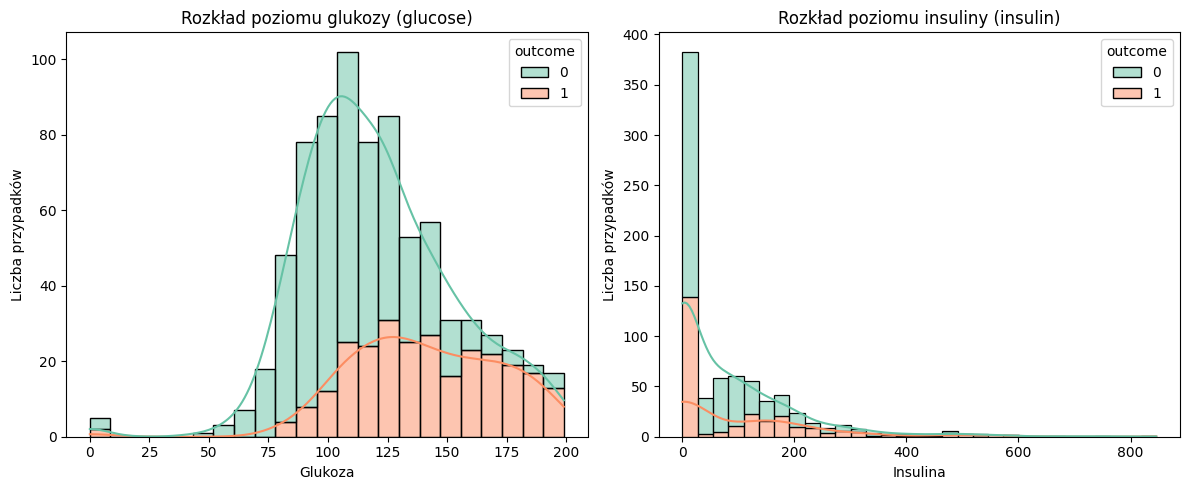

In [4]:
class_share = df["outcome"].value_counts(normalize=True)
print(f"udział każdej klasy w outcome: {class_share}\n")

nones = df.isna().sum()
print(f"liczba brakujących danych: {nones}\n")

zeros = df.eq(0).sum()
print(f"liczba zer w każdej z kolumn: {zeros}\n")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(
  data=df,
  x='glucose',
  hue='outcome',
  ax=axes[0],
  kde=True,
  palette='Set2',
  multiple='stack',
)
axes[0].set_title('Rozkład poziomu glukozy (glucose)')
axes[0].set_xlabel('Glukoza')
axes[0].set_ylabel('Liczba przypadków')

sns.histplot(
  data=df,
  x='insulin',
  hue='outcome',
  ax=axes[1],
  kde=True,
  palette='Set2',
  multiple='stack',
)
axes[1].set_title('Rozkład poziomu insuliny (insulin)')
axes[1].set_xlabel('Insulina')
axes[1].set_ylabel('Liczba przypadków')

plt.tight_layout()
plt.show()

In [5]:
# TEST
assert abs(class_share[0] - 0.651) < 1e-3
assert zeros["insulin"] == 374 and zeros["glucose"] == 5 and zeros["pregnancies"] == 111
print("2 OK")

2 OK


*Twoja odpowiedź:*
1. Jaką accuracy osiągnie baseline?
2. W których kolumnach zero jest **fizycznie niemożliwe** (żyjący człowiek nie może mieć takiej wartości), a w której jest zupełnie normalne?
3. Która cecha najwyraźniej różni chore i zdrowe pacjentki?

> 1. Baseline osiągnie accuracy równe udziałowi klasy 0.

> 2. Fizycznie niemożliwe zera są w:
    <ul>
      <li>glucose</li>
      <li>blood_preassure</li>
      <li>skin_thickness</li>
      <li>insulin</li>
      <li>bmi</li>
    </ul>
Normalne zera:
    <ul>
      <li>pregnancies</li>
      <li>outcome</li>
    </ul>

> 3. `glucose` najwyraźniej różni chore i zdrowe pacjentki.

---
## 3. Zamiana ukrytych braków na `NaN`
W kolumnach `glucose`, `blood_pressure`, `skin_thickness`, `insulin`, `bmi` zamień zera na `np.nan` (`replace(0, np.nan)`). Wynik zapisz w `df_clean` (kopia `df`), a liczbę braków w każdej kolumnie w `missing`.

Model nie wie, że zero oznacza brak. Dla niego „insulina = 0” to po prostu bardzo niska insulina – a takich „pomiarów” jest prawie połowa.

In [6]:
impossible_zeros_cols = [
  "glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"
]

df_clean = df.copy()
df_clean[impossible_zeros_cols] = df_clean[impossible_zeros_cols].replace(0, np.nan)

missing = df_clean.isna().sum()
missing

,0
pregnancies,0
glucose,5
blood_pressure,35
skin_thickness,227
insulin,374
bmi,11
pedigree,0
age,0
outcome,0


In [7]:
# TEST
assert missing["insulin"] == 374 and missing["skin_thickness"] == 227 and missing["pregnancies"] == 0
assert (df["insulin"] == 0).sum() == 374, "Nie zmieniaj oryginalnego df - użyj copy()"
print("3 OK")

3 OK


*Twoja odpowiedź:* insuliny brakuje u prawie połowy pacjentek. Jakie masz możliwości? Co wybierasz i dlaczego?

> 1. usunięcie wierszy z brakami: tracimy połowe zbioru danych.
2. usunięcie całej kolumny `insulin`: rozwiązujemy problem braków,<br>
ale tracimy kluczową informację biologiczną.
3. imputacja prosta (średnia | mediana): zachowyjemy rozmiar zbioru,<br>
ale sztucznie spłaszczamy rozkład danych.
4. imputacja zaawansowana: np. KNN Imputer czy iterative imputer.

> Wybrałbym 4. opcję, ponieważ poziom insuliny zależy od innych parametrów.
Zwykła mediana wrzuci wszystkim tę samą wartość. Np. jeśli pacjentka ma wysokie BMI i wysoki poziom glukozy, KNN Imputer oszacuje jej brakującą insulinę na podstawie innych pacjentek o podobnym profilu.


---
## 4. Podział i przygotowanie
1. `X` – wszystkie cechy z `df_clean`, `y` – `outcome`. Podziel na `X_train, X_test, y_train, y_test` (`test_size=0.25`, `stratify=y`, `random_state=42`).
2. Napisz funkcję `model_z(klasyfikator)`, która zwraca pipeline: `SimpleImputer(strategy="median")` → `StandardScaler()` → klasyfikator. (Wszystkie cechy są liczbowe, więc `ColumnTransformer` nie jest potrzebny.)
3. Utwórz `cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`.

In [8]:
X = df_clean.drop(columns=['outcome'])
y = df_clean['outcome']

X_train, X_test, y_train, y_test = train_test_split(
  X, y, test_size=0.25, stratify=y, random_state=42
)

def model_z(klasyfikator):
  return Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', klasyfikator),
  ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [9]:
# TEST
assert X_train.shape == (576, 8) and X_test.shape == (192, 8)
assert X_train["insulin"].isna().sum() > 0, "Podział robimy na df_clean (z NaN zamiast zer)"
assert len(model_z(None).steps) == 3
print("4 OK")

4 OK


---
## 5. Porównanie klasyfikatorów walidacją krzyżową
Dla pięciu modeli z domyślnymi hiperparametrami: `DummyClassifier(strategy="most_frequent")`, `LogisticRegression()`, `KNeighborsClassifier()`, `DecisionTreeClassifier(random_state=42)`, `RandomForestClassifier(random_state=42)` policz `cross_val_score` na zbiorze treningowym i accuracy na całym zbiorze treningowym.

Zbierz wyniki w tabeli `porownanie` (indeks: `"baseline"`, `"regresja logistyczna"`, `"kNN"`, `"drzewo decyzyjne"`, `"las losowy"`; kolumny: `"CV średnia"`, `"CV odch."`, `"train"`) i narysuj wykres słupkowy średnich z odchyleniami.

Tabela wyników:
                      CV średnia  CV odch.     train
baseline                0.651049  0.002249  0.651042
regresja logistyczna    0.777856  0.024709  0.789931
kNN                     0.736132  0.020716  0.835069
drzewo decyzyjne        0.713568  0.024244  1.000000
las losowy              0.748291  0.014015  1.000000


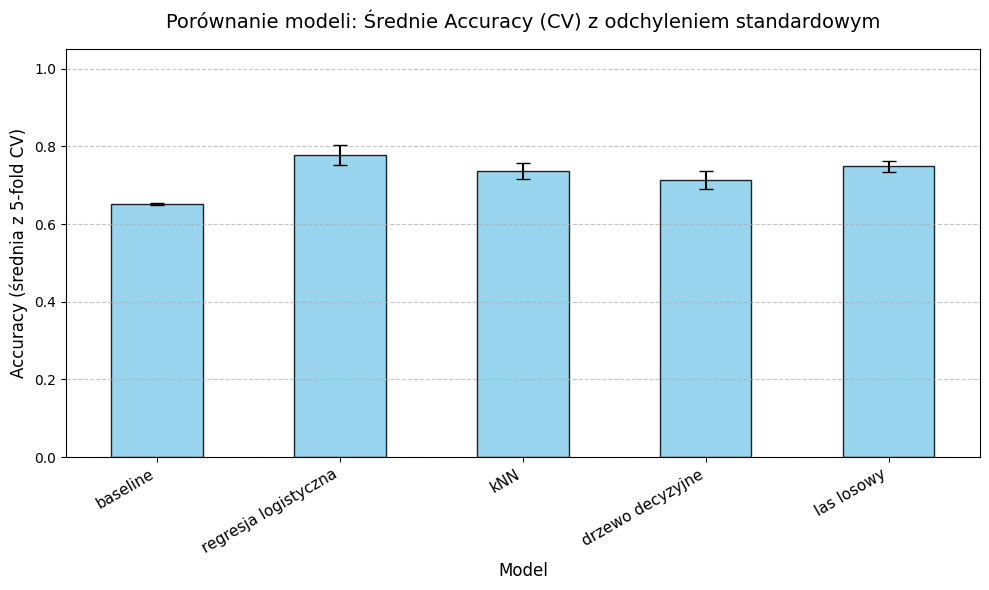

In [10]:
models = {
  'baseline': DummyClassifier(strategy='most_frequent'),
  'regresja logistyczna': LogisticRegression(random_state=42),
  'kNN': KNeighborsClassifier(),
  'drzewo decyzyjne': DecisionTreeClassifier(random_state=42),
  'las losowy': RandomForestClassifier(random_state=42)
}

results = []
for name, clf in models.items():
  pipe = model_z(clf)

  cv_scores = cross_val_score(
    pipe, X_train, y_train, cv=cv, scoring='accuracy'
  )
  cv_mean = cv_scores.mean()
  cv_std = cv_scores.std()

  pipe.fit(X_train, y_train)
  train_acc = pipe.score(X_train, y_train)

  results.append({
    'CV średnia': cv_mean,
    'CV odch.': cv_std,
    'train': train_acc,
  })

porownanie = pd.DataFrame(
  results,
  index=[
    'baseline',
    'regresja logistyczna',
    'kNN',
    'drzewo decyzyjne',
    'las losowy',
  ],
)

print('Tabela wyników:')
print(porownanie)

fig, ax = plt.subplots(figsize=(10, 6))

porownanie['CV średnia'].plot(
    kind='bar',
    yerr=porownanie['CV odch.'],
    ax=ax,
    capsize=5,
    color='skyblue',
    edgecolor='black',
    alpha=0.85,
)

ax.set_title(
    'Porównanie modeli: Średnie Accuracy (CV) z odchyleniem standardowym',
    fontsize=14,
    pad=15,
)
ax.set_ylabel('Accuracy (średnia z 5-fold CV)', fontsize=12)
ax.set_xlabel('Model', fontsize=12)
ax.set_ylim(0, 1.05)
plt.xticks(rotation=30, ha='right', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [11]:
# TEST
assert list(porownanie.index) == ["baseline", "regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"]
assert abs(porownanie.loc["baseline", "CV średnia"] - 0.651) < 1e-2
assert abs(porownanie.loc["regresja logistyczna", "CV średnia"] - 0.778) < 1e-2
assert porownanie.loc["drzewo decyzyjne", "train"] > 0.99
print("5 OK")

5 OK


---
## 6. Krzywa walidacji dla kNN
Policz `validation_curve` dla `kneighborsclassifier__n_neighbors` w `ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]`. Wyniki zapisz w `tren`, `walid`; narysuj średnie (trening i walidacja) w funkcji k.

Średnie wyniki na zbiorze treningowym (tren): [[1.         1.         1.         1.         1.        ]
 [0.8673913  0.86334056 0.88503254 0.85249458 0.83947939]
 [0.85217391 0.8373102  0.84815618 0.82863341 0.83947939]
 [0.81956522 0.84381779 0.84598698 0.81778742 0.80694143]
 [0.82608696 0.82429501 0.82646421 0.79826464 0.80477223]
 [0.80869565 0.80043384 0.8308026  0.79392625 0.80694143]
 [0.80434783 0.80477223 0.80694143 0.79609544 0.79392625]
 [0.78695652 0.76572668 0.78958785 0.78958785 0.78308026]
 [0.76304348 0.76572668 0.77006508 0.77874187 0.76355748]]
Średnie wyniki na zbiorze walidacyjnym (walid): [[0.6637931  0.67826087 0.70434783 0.67826087 0.72173913]
 [0.71551724 0.73913043 0.66956522 0.76521739 0.7826087 ]
 [0.72413793 0.74782609 0.70434783 0.73913043 0.76521739]
 [0.75       0.73043478 0.71304348 0.74782609 0.75652174]
 [0.76724138 0.76521739 0.73043478 0.79130435 0.8       ]
 [0.75862069 0.76521739 0.73043478 0.8        0.83478261]
 [0.75       0.76521739 0.74782609 

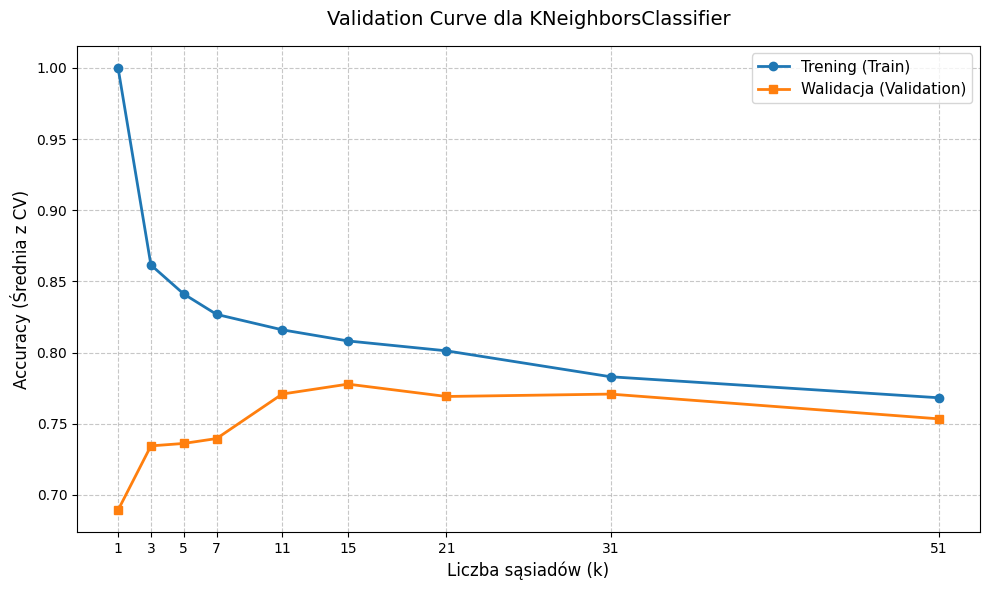

In [12]:
ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]

knn_pipe = model_z(KNeighborsClassifier())

train_scores, valid_scores = validation_curve(
  knn_pipe,
  X_train,
  y_train,
  param_name='classifier__n_neighbors',
  param_range=ks,
  cv=cv,
  scoring='accuracy',
)

tren = train_scores
walid = valid_scores

print('Średnie wyniki na zbiorze treningowym (tren):', tren)
print('Średnie wyniki na zbiorze walidacyjnym (walid):', walid)

plt.figure(figsize=(10, 6))
plt.plot(ks, tren.mean(axis=1), marker='o', label='Trening (Train)', linewidth=2)
plt.plot(
    ks, walid.mean(axis=1), marker='s', label='Walidacja (Validation)', linewidth=2
)

plt.title('Validation Curve dla KNeighborsClassifier', fontsize=14, pad=15)
plt.xlabel('Liczba sąsiadów (k)', fontsize=12)
plt.ylabel('Accuracy (Średnia z CV)', fontsize=12)
plt.xticks(ks)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

In [13]:
# TEST
assert tren.shape == (9, 5) and walid.shape == (9, 5)
assert tren.mean(axis=1)[0] == 1.0, "Dla k=1 wynik treningowy powinien wynosić 1.0"
print("6 OK")

6 OK


*Twoja odpowiedź:* dlaczego dla k = 1 wynik treningowy wynosi dokładnie 1.0? Gdzie jest przeuczenie, a gdzie niedouczenie?

> Dla k = 1 algorytm szuka 1 najbliższego sąsiada w zbiorze treningowym dla każdego punktu.
Jeśli testujemy model na tym samym zbiorze, na którym się uczył, to najbliższym sąsiadem każdego punktu jest on sam. Przez to model zawsze odpowie poprawnie.

> Przeuczenie jest po lewej stronie: małe k, np. 1,3.

> Niedouczenie po prawej stronie wykresu: duże k

---
## 7. Strojenie: `GridSearchCV`
Dla każdego z czterech klasyfikatorów uruchom `GridSearchCV(model_z(...), siatka, cv=cv)` na zbiorze treningowym. Siatki:
- regresja logistyczna: `C` ∈ {0.01, 0.1, 1, 10, 100},
- kNN: `n_neighbors` ∈ {1, 3, 5, 7, 11, 15, 21, 31},
- drzewo: `max_depth` ∈ {2, 3, 4, 5, 6, 8, None},
- las losowy: `max_depth` ∈ {3, 5, 8, None}, `n_estimators` ∈ {100, 300}.

Nauczone obiekty zapisz w słowniku `wyniki_gs` (klucze jak w punkcie 5, bez baseline'u) i wypisz najlepsze parametry oraz `best_score_` każdego modelu.

In [14]:
grids = {
  'regresja logistyczna': {
    'estimator': LogisticRegression(random_state=42),
    'param_grid': {'classifier__C': [0.01, 0.1, 1, 10, 100]},
  },
  'kNN': {
    'estimator': KNeighborsClassifier(),
    'param_grid': {
      'classifier__n_neighbors': [1, 3, 5, 7, 11, 15, 21, 31]
    },
  },
  'drzewo decyzyjne': {
    'estimator': DecisionTreeClassifier(random_state=42),
    'param_grid': {'classifier__max_depth': [2, 3, 4, 5, 6, 8, None]},
  },
  'las losowy': {
    'estimator': RandomForestClassifier(random_state=42),
    'param_grid': {
      'classifier__max_depth': [3, 5, 8, None],
      'classifier__n_estimators': [100, 300],
    },
  },
}

wyniki_gs = {}
for name, config in grids.items():
  pipe = model_z(config['estimator'])

  gs = GridSearchCV(
    estimator=pipe,
    param_grid=config['param_grid'],
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
  )

  gs.fit(X_train, y_train)

  wyniki_gs[name] = gs

  print(f'Model: {name}')
  print(f'  Najlepsze parametry: {gs.best_params_}')
  print(f'  Najlepszy wynik (CV accuracy): {gs.best_score_:.4f}')
  print('-' * 40)

Model: regresja logistyczna
  Najlepsze parametry: {'classifier__C': 1}
  Najlepszy wynik (CV accuracy): 0.7779
----------------------------------------
Model: kNN
  Najlepsze parametry: {'classifier__n_neighbors': 15}
  Najlepszy wynik (CV accuracy): 0.7778
----------------------------------------
Model: drzewo decyzyjne
  Najlepsze parametry: {'classifier__max_depth': 5}
  Najlepszy wynik (CV accuracy): 0.7500
----------------------------------------
Model: las losowy
  Najlepsze parametry: {'classifier__max_depth': 3, 'classifier__n_estimators': 300}
  Najlepszy wynik (CV accuracy): 0.7622
----------------------------------------


In [15]:
# TEST
assert set(wyniki_gs) == {"regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"}
assert all(hasattr(gs, "best_estimator_") for gs in wyniki_gs.values())
assert all(gs.best_score_ > 0.7 for gs in wyniki_gs.values())
print("7 OK")

7 OK


---
## 8. Wybór modelu i ocena końcowa
1. `najlepszy` – nazwa modelu z najwyższym `best_score_`; `model_koncowy` – jego `best_estimator_`.
2. `acc_test` – accuracy `model_koncowy` na zbiorze testowym (**jedyny raz, kiedy używasz `X_test`**).
3. Macierz pomyłek (`ConfusionMatrixDisplay`) i `classification_report`.

Najlepszy model to: regresja logistyczna
Z najlepszym wynikiem CV: 0.7779
Użyte hiperparametry: {'classifier__C': 1}

Accuracy na zbiorze testowym (acc_test): 0.7240

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.84      0.80       125
           1       0.63      0.51      0.56        67

    accuracy                           0.72       192
   macro avg       0.70      0.67      0.68       192
weighted avg       0.72      0.72      0.72       192



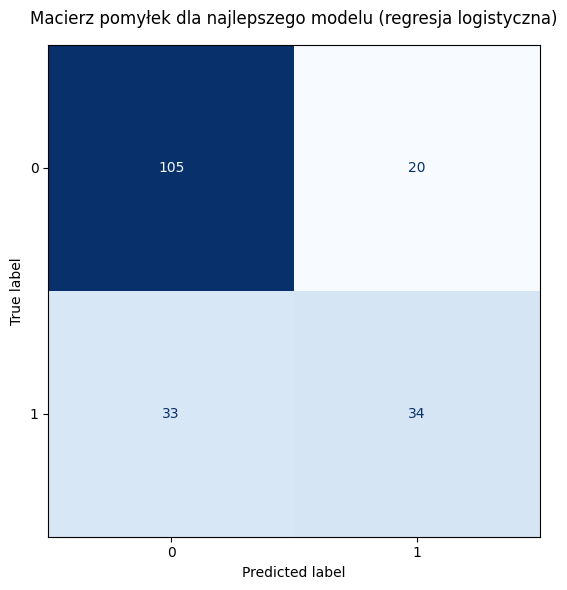

In [16]:
najlepszy = max(wyniki_gs, key=lambda k: wyniki_gs[k].best_score_)
model_koncowy = wyniki_gs[najlepszy].best_estimator_

print(f'Najlepszy model to: {najlepszy}')
print(f'Z najlepszym wynikiem CV: {wyniki_gs[najlepszy].best_score_:.4f}')
print(f'Użyte hiperparametry: {wyniki_gs[najlepszy].best_params_}\n')

y_pred = model_koncowy.predict(X_test)
acc_test = accuracy_score(y_test, y_pred)
print(f'Accuracy na zbiorze testowym (acc_test): {acc_test:.4f}\n')

print('Classification Report:')
print(classification_report(y_test, y_pred))

fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(
  y_test, y_pred, ax=ax, cmap='Blues', values_format='d', colorbar=False
)
ax.set_title(
  f'Macierz pomyłek dla najlepszego modelu ({najlepszy})',
  fontsize=12,
  pad=15,
)
plt.tight_layout()
plt.show()

In [17]:
# TEST
assert najlepszy == max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
assert 0.65 < acc_test < 0.9
print("8 OK")

8 OK


*Twoja odpowiedź:*
1. Jak wynik testowy ma się do szacunku z walidacji krzyżowej? Czy różnica cię niepokoi? (Zbiór testowy ma 192 pacjentki – ile p.p. to jedna osoba?)
2. Jaki jest recall dla klasy „cukrzyca”? Co oznacza on dla pacjentek? Czy accuracy to dobra metryka do wyboru modelu w tym zastosowaniu?
3. Modele w czołówce różnią się w CV o 1–2 p.p., a odchylenia wynoszą ok. 2–3 p.p. Czy można jednoznacznie wskazać „najlepszy” algorytm?

> 1. Waga jednej osoby to 0.52 p.p.<br>
Wynik na zbiorze testowym i wynik z walidacji krzyżowej zazwyczaj różnią się 1-3 p.p. Ponieważ 1 osoba to 0.52 p.p. niewielka różnica rzędu 1-2 p.p. jest normalna i wynika z wariancji statystycznej oraz losowego podziału na zbiór testowy.

> 2. recall dla klasy "cukrzyca" to odsetek chorych pacjentek, które model poprawnie wykrył spośród wszystkich rzeczywiście chorych.<br>
Wysoki recall oznacza, że mało chorych zostało "przeoczonych". Niski oznacza, że model mówi chorej pacjentce, że jest zdrowa.<br>
accuracy nie jest dobrą metryką. Zbiór jest niezbalansowany (65% zdrowych, 35% chorych) i model, który zawsze mówi "brak cukrzycy", miałby accuracy 65%. Niby dobry, ale jest bezużyteczny. Poza tym, w medycynie koszt wyniku FN jest gigantyczny, więc lepszymi metrykami byłyby recall, precision czy F1-score.

> 3. Nie. Różnice 1-2 p.p. przy odchyleniach 2-3 p.p. oznaczają nakładanie się przedziałów błedu. Wybiera się wtedy model najprostszy.

---
## 9. Dla chętnych
1. Powtórz punkty 7–8 z `scoring="recall"` w `GridSearchCV`. Czy zmienił się wybrany model? Co stało się z precision?
2. Dodaj do imputera `add_indicator=True` (flagi braków). Czy sam fakt braku pomiaru insuliny niesie informację?
3. Sprawdź, jak wyglądałyby wyniki, gdyby zostawić zera zamiast `NaN` (punkt 3 pominięty). Czy różnica jest duża? Dlaczego może być mała?